# List of 20 countries
First, we scrape Wikipedia to get the top 20 countries by GDP, then sort them by GDP per capita.

The id of each country would also indicate its rank (GDP per capita)

In [45]:
import pandas as pd, requests as req

In [48]:
'''
    Getting the top 20 countries based on GDP (source : Wikipedia)
'''

def get_top_countries(num_countries=20):
    from io import StringIO
    import re

    url_gdp_capita = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)_per_capita"
    url_gdp = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
    url_population = "https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_population"
    
    headers = {
        "User-Agent": "Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:154.0) Gecko/20100101 Firefox/154.0",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
        "Accept-Language": "en-US,en;q=0.5",
        "Accept-Encoding": "gzip, deflate, br, zstd",
        "Connection": "keep-alive",
        "Upgrade-Insecure-Requests": "1",
        "Sec-Fetch-Dest": "document",
        "Sec-Fetch-Mode": "navigate",
        "Sec-Fetch-Site": "none",
        "Sec-Fetch-User": "?1",
    } # To emulate firefox headers
    
    
    response = req.get(url_gdp, headers=headers)
    page_gdp = pd.read_html(StringIO(response.text))
    
    response = req.get(url_gdp_capita, headers=headers)
    page_gdp_capita = pd.read_html(StringIO(response.text))

    response = req.get(url_population, headers=headers)
    page_population = pd.read_html(StringIO(response.text))
    
    # Get the list of top GDP countries
    for i, table in enumerate(page_gdp):
        if table.shape[0]>200:
            countries = table[1:num_countries+1][["Country/Territory","World Bank (2025)[6]"]] # The table includes one extra row as cumulative global GDP
            countries["Country/Territory"] = countries["Country/Territory"].map(lambda c:
                re.findall(r"^[^\[]*", c)[0])

    # Get the countries population
    for i, table in enumerate(page_population):
        if table.shape[0]>200:
            population = table[1:][["Location","Population"]] # The table includes one extra row as cumulative global population
            population = population.dropna()
            population["Location"] = population["Location"].map(lambda c:
                re.findall(r"^[^\[]*", c)[0]).str.lower()

    # Sort them based on GDP per capita
    for i, table in enumerate(page_gdp_capita):
        if table.shape[0]>200:
            table = table.dropna(subset="Country/Territory")
            table["Country/Territory"] = table["Country/Territory"].map(lambda c:
                re.findall(r"^[^\[]*", c)[0])
            countries = pd.merge(countries
                                 , table
                                 , on="Country/Territory"
                                 , suffixes=("","_capita"))

            countries["Country/Territory"] = countries["Country/Territory"].str.lower()
            countries = countries[["Country/Territory","World Bank (2025)[6]","World Bank (2025)[6]_capita"]]
            countries = countries.rename(columns={"Country/Territory":"country"
                                      ,"World Bank (2025)[6]":"wb25_gdp_milusd"
                                      ,"World Bank (2025)[6]_capita":"wb25_gdpcapita_usd"}
                             )
            countries = countries.astype({
                            "country": "string",
                            "wb25_gdp_milusd": "int",
                            "wb25_gdpcapita_usd": "int",
                        })
            population = population.loc[population["Location"].isin(countries["country"])]
            population = population.rename(columns = {"Location": "country",
                                        "Population": "population_mil"}
                              )
            population["population_mil"] /= 10**6
            countries = pd.merge(countries
                                 , population
                                 , on =  "country")
            
            countries = countries.sort_values(by="wb25_gdpcapita_usd",ascending=False)

            
            countries = countries.reset_index(drop=True)
            return countries
    return None

top_economy_countries = get_top_countries()
top_economy_countries['id'] = top_economy_countries.index+1
top_economy_countries = top_economy_countries[["id"]+[col for col in top_economy_countries.columns[:-1]]]
top_economy_countries

,id,country,wb25_gdp_milusd,wb25_gdpcapita_usd,population_mil
0,1,switzerland,1043530,114769,9.154896
1,2,united states,30769700,90027,341.784857
2,3,netherlands,1332768,73684,18.192693
3,4,australia,1798519,65130,27.921150
4,5,germany,5050923,60496,83.298787
5,6,united kingdom,4002588,57602,69.487000
6,7,canada,2319900,55698,41.798407
7,8,france,3366316,48986,69.081996
8,9,italy,2551557,43309,58.949500
9,10,spain,1906453,38627,49.935642


# WorldBank data
WorldBank's API provides access to all the datasets (sources), their sub-series (indicators), and metadata (concepts)

The endpoints to access each series in the 2nd version of their api ([https://api.worldbank.org/v2/](https://api.worldbank.org/v2/)) is given by 

    /country/{COUNTRY_ID}/indicator/{INDICATOR_ID}/source/{SOURCE_ID}/

Multiple IDs are supported using the separator (`;`). To download the available data in CSV format

    /country/{COUNTRY_ID}/indicator/{INDICATOR_ID}/source/{SOURCE_ID}?downloadformat=CSV

----

The dataset we retrieve series from is the World Development Indicators with id=2 and Health Nutrition and Population Statistics id=16 ([https://api.worldbank.org/v2/sources](https://api.worldbank.org/v2/sources))

In [3]:
BASE_URL = "https://api.worldbank.org/v2/"
DATASET_ID = ["2", ## Corresponds to World Development Indicators
             "16" ## Corresponds to Health Nutrition and Population Statistics
             ] 

## Country codes

In [4]:
response = req.get("https://api.worldbank.org/v2/country?format=json",params={"per_page":1000})
response.raise_for_status()
country_wd = pd.json_normalize(response.json()[1]) ## The 0th element is the metadata
country_wd = country_wd[["id","name"]]
country_wd = country_wd.rename(columns={"id":"codename","name":"country"})
country_wd.country = country_wd.country.str.lower()

temp_df = top_economy_countries.merge(country_wd,on="country")
temp_df

,country,wb25_gdp_milusd,wb25_gdpcapita_usd,population_mil,id,codename
0,switzerland,1043530,114769,9.154896,1,CHE
1,united states,30769700,90027,341.784857,2,USA
2,netherlands,1332768,73684,18.192693,3,NLD
3,australia,1798519,65130,27.921150,4,AUS
4,germany,5050923,60496,83.298787,5,DEU
5,united kingdom,4002588,57602,69.487000,6,GBR
6,canada,2319900,55698,41.798407,7,CAN
7,france,3366316,48986,69.081996,8,FRA
8,italy,2551557,43309,58.949500,9,ITA
9,spain,1906453,38627,49.935642,10,ESP


In [5]:
top_economy_countries.loc[~top_economy_countries.country.isin(temp_df.country),"country"]

10    south korea
13         turkey
14         russia
Name: country, dtype: object

We need to find the corresponding names

In [6]:
print(f'{"name in our data":>20} | {"available names in WorldBank":<40}')
print('-'*100)
for country in top_economy_countries.loc[~top_economy_countries.country.isin(temp_df.country),"country"]:
    print(f'{country:>20} | {" ,".join(country_wd.country[country_wd.country.str.contains(country)]):<40}')
    print('-'*100)

    name in our data | available names in WorldBank            
----------------------------------------------------------------------------------------------------
         south korea |                                         
----------------------------------------------------------------------------------------------------
              turkey |                                         
----------------------------------------------------------------------------------------------------
              russia | russian federation                      
----------------------------------------------------------------------------------------------------


Since I couldn't resolve the issue I will look for them individually.

In [7]:
print(f'{"name in our data":>20} | {"available names in WorldBank":<40}')
print('-'*100)
print(f'{"korea":>20} | {" ,".join(country_wd.country[country_wd.country.str.contains("korea")]):<40}')
print('-'*100)
print(f'{"turkey":>20} | {" ,".join(country_wd.country[country_wd.country.str.contains("tur")]):<40}')
print('-'*100)

    name in our data | available names in WorldBank            
----------------------------------------------------------------------------------------------------
               korea | korea, rep. ,korea, dem. people's rep.  
----------------------------------------------------------------------------------------------------
              turkey | turks and caicos islands ,turkmenistan ,turkiye
----------------------------------------------------------------------------------------------------


In [8]:
country_wd.loc[country_wd.country=='russian federation','country'] = 'russia'
country_wd.loc[country_wd.country=='korea, rep.','country'] = 'south korea'
country_wd.loc[country_wd.country=='turkiye','country'] = 'turkey'

In [9]:
top_economy_countries.merge(country_wd,on="country")

,country,wb25_gdp_milusd,wb25_gdpcapita_usd,population_mil,id,codename
0,switzerland,1043530,114769,9.154896,1,CHE
1,united states,30769700,90027,341.784857,2,USA
2,netherlands,1332768,73684,18.192693,3,NLD
3,australia,1798519,65130,27.921150,4,AUS
4,germany,5050923,60496,83.298787,5,DEU
5,united kingdom,4002588,57602,69.487000,6,GBR
6,canada,2319900,55698,41.798407,7,CAN
7,france,3366316,48986,69.081996,8,FRA
8,italy,2551557,43309,58.949500,9,ITA
9,spain,1906453,38627,49.935642,10,ESP


In [10]:
top_economy_countries = top_economy_countries.merge(country_wd,on="country")

## Collecting the data

I have gathered the list of tables I need from their [Data Bank](https://databank.worldbank.org/source/world-development-indicators/) below. Key 2 refers to `World Development Indicators` and 16 to the `Health Nutrition and Population Statistics` datasets

In [11]:
LIST_TABLES = {
    "2":[
    "Current health expenditure (% of GDP)",
    "Current health expenditure per capita (current US$)",
    "Death rate, crude (per 1,000 people)",
    "Educational attainment, Doctoral or equivalent, population 25+, total (%) (cumulative)",
    "Educational attainment, at least Master's or equivalent, population 25+, total (%) (cumulative)",
    "Educational attainment, at least completed upper secondary, population 25+, total (%) (cumulative)",
    "Educational attainment, at least completed primary, population 25+ years, total (%) (cumulative)",
    "Educational attainment, at least Bachelor's or equivalent, population 25+, total (%) (cumulative)",
    "Educational attainment, at least Bachelor's or equivalent, population 25+, male (%) (cumulative)",
    "Educational attainment, at least Bachelor's or equivalent, population 25+, female (%) (cumulative)",
    "Educational attainment, at least Master's or equivalent, population 25+, male (%) (cumulative)",
    "Educational attainment, at least Master's or equivalent, population 25+, female (%) (cumulative)",
    "Educational attainment, Doctoral or equivalent, population 25+, male (%) (cumulative)",
    "Educational attainment, Doctoral or equivalent, population 25+, female (%) (cumulative)",
    "Export unit value index (2015 = 100)",
    "Export value index (2015 = 100)",
    "Export volume index (2015 = 100)",
    "Exports of goods and services (% of GDP)",
    "Exports of goods and services (annual % growth)",
    "GDP (current US$)",
    "Government expenditure on education, total (% of GDP)",
    "Labor force, total",
    "Life expectancy at birth, total (years)",
    "Primary education, pupils",
    "Population, total",
    "Secondary education, pupils",
    "Secondary education, pupils (% female)",
    "Share of youth not in education, employment or training, female (% of female youth population)",
    "Share of youth not in education, employment or training, male (% of male youth population)",
    "Share of youth not in education, employment or training, total (% of youth population)",
    "Unemployment with advanced education (% of total labor force with advanced education)",
    "Unemployment with advanced education, female (% of female labor force with advanced education)",
    "Unemployment with advanced education, male (% of male labor force with advanced education)",
    "Unemployment with basic education (% of total labor force with basic education)",
    "Unemployment with basic education, female (% of female labor force with basic education)",
    "Unemployment with basic education, male (% of male labor force with basic education)",
    "Unemployment with intermediate education (% of total labor force with intermediate education)",
    "Unemployment with intermediate education, female (% of female labor force with intermediate education)",
    "Unemployment with intermediate education, male (% of male labor force with intermediate education)"
    ],
    "16":[
    "Prevalence of overweight (% of children under 5)",
    "Prevalence of overweight (% of adults)",
    "Suicide mortality rate (per 100,000 population)",
    "Suicide mortality rate, female (per 100,000 female population)",
    "Suicide mortality rate, male (per 100,000 male population)",
    "Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)",
    "Total alcohol consumption per capita, female (liters of pure alcohol, projected estimates, female 15+ years of age)",
    "Total alcohol consumption per capita, male (liters of pure alcohol, projected estimates, male 15+ years of age)",
]
}

**ID of each table**

In [13]:
params = {
    "format": "json",
    "per_page": 2000,
    "page": 1
}

list_indicators=[]
while True:
    response = req.get(f"https://api.worldbank.org/v2/indicator",params=params)
    response.raise_for_status()
    meta = response.json()[0]
    df = pd.json_normalize(response.json()[1])
    condition = df["name"].isin(LIST_TABLES['2']+LIST_TABLES['16'])
    df = df.loc[condition]
    if len(df)>0:
        df = df.loc[~((df['sourceNote']=='NaN') | (df['sourceNote'].isna()) | (df['sourceNote']==''))]
        list_indicators.append(df)
        if len(list_indicators[-1])==0:
            list_indicators.pop()
    
    if meta["page"] == meta["pages"]:
        break

    params["page"] += 1
    print(f"Finished page {meta["page"]}")

indicators_df = pd.concat(list_indicators)
indicators_df = indicators_df.sort_values(by="name")
indicators_df

Finished page 1
Finished page 2
Finished page 3
Finished page 4
Finished page 5
Finished page 6
Finished page 7
Finished page 8
Finished page 9
Finished page 10
Finished page 11
Finished page 12
Finished page 13
Finished page 14


,id,name,unit,sourceNote,sourceOrganization,topics,source.id,source.value
82,SH.XPD.CHEX.GD.ZS,Current health expenditure (% of GDP),,Level of current health expenditure expressed ...,"Global Health Expenditure Database, updated De...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
83,SH.XPD.CHEX.PC.CD,Current health expenditure per capita (current...,,Current expenditures on health per capita in c...,"Global Health Expenditure Database, updated De...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
521,SP.DYN.CDRT.IN,"Death rate, crude (per 1,000 people)",,Crude death rate indicates the number of death...,"World Population Prospects, United Nations (UN...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
960,SE.TER.CUAT.DO.FE.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
961,SE.TER.CUAT.DO.MA.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
962,SE.TER.CUAT.DO.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
957,SE.TER.CUAT.BA.FE.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
958,SE.TER.CUAT.BA.MA.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
959,SE.TER.CUAT.BA.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
963,SE.TER.CUAT.MS.FE.ZS,"Educational attainment, at least Master's or e...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators


In [15]:
indicators_df.shape[0], len(LIST_TABLES["2"]),len(LIST_TABLES["16"])

(46, 39, 8)

In [16]:
for idx in LIST_TABLES:
    print(f'For source: {idx} these were not found: '+', '.join([i for i in LIST_TABLES[idx] if i not in list(indicators_df["name"])]))

For source: 2 these were not found: 
For source: 16 these were not found: Prevalence of overweight (% of children under 5)


Since there's only one table we couldn't find, I will simply find the ID through WorldBank databank.

In [17]:
id_ = 'SH.STA.OWGH.ZS'
params = {
    "format": "json",
    "per_page": 2000,
    "page": 1
}

list_indicators=[]
while True:
    response = req.get(f"https://api.worldbank.org/v2/indicator",params=params)
    response.raise_for_status()
    meta = response.json()[0]
    df = pd.json_normalize(response.json()[1])
    condition = (df.id==id_)
    df = df.loc[condition]
    if len(df)>0:
        list_indicators.append(df)
        if len(list_indicators[-1])==0:
            list_indicators.pop()
    
    if meta["page"] == meta["pages"]:
        break

    params["page"] += 1
    print(f"Finished page {meta["page"]}")

temp_df = pd.concat(list_indicators)
temp_df

Finished page 1
Finished page 2
Finished page 3
Finished page 4
Finished page 5
Finished page 6
Finished page 7
Finished page 8
Finished page 9
Finished page 10
Finished page 11
Finished page 12
Finished page 13
Finished page 14


,id,name,unit,sourceNote,sourceOrganization,topics,source.id,source.value
1985,SH.STA.OWGH.ZS,"Prevalence of overweight, weight for height (%...",,Prevalence of overweight children is the perce...,"UNICEF, WHO, World Bank: Joint child Malnutrit...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators


It seems despite the DataBank's naming, the codename does not corresponds to the same exact same Indicator.

In [18]:
indicators_df = pd.concat((indicators_df,temp_df))

So now that I have gathered all the codes, I can move on to retrieve the data. I will retrieve the data based on the country's name.

**Metadata**

In [19]:
headers = {
    "User-Agent": "Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Connection": "keep-alive",
    "Upgrade-Insecure-Requests": "1",
    "Sec-Fetch-Dest": "document",
    "Sec-Fetch-Mode": "navigate",
    "Sec-Fetch-Site": "none",
    "Sec-Fetch-User": "?1",
    "Priority": "u=0, i",
}

In [20]:
list_metadata = []
for indicator in indicators_df.id:
    print(f"Collecting metadata for {indicator}")
    while True:
        try:
            response = req.get(f"https://api.worldbank.org/v2/indicator/{indicator}?format=json",timeout=15,headers=headers)
            break
        except:
            pass
    
    response.raise_for_status()
    meta = response.json()[0]
    list_metadata.append(pd.json_normalize(response.json()[1]))


metadata_df = pd.concat(list_metadata)
metadata_df

,id,name,unit,sourceNote,sourceOrganization,topics,source.id,source.value
0,SH.XPD.CHEX.GD.ZS,Current health expenditure (% of GDP),,Level of current health expenditure expressed ...,"Global Health Expenditure Database, updated De...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
0,SH.XPD.CHEX.PC.CD,Current health expenditure per capita (current...,,Current expenditures on health per capita in c...,"Global Health Expenditure Database, updated De...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
0,SP.DYN.CDRT.IN,"Death rate, crude (per 1,000 people)",,Crude death rate indicates the number of death...,"World Population Prospects, United Nations (UN...","[{'id': '8', 'value': 'Health '}]",2,World Development Indicators
0,SE.TER.CUAT.DO.FE.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.DO.MA.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.DO.ZS,"Educational attainment, Doctoral or equivalent...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.BA.FE.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.BA.MA.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.BA.ZS,"Educational attainment, at least Bachelor's or...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators
0,SE.TER.CUAT.MS.FE.ZS,"Educational attainment, at least Master's or e...",,The percentage of population ages 25 and over ...,"Data API, UN Educational, Scientific and Cultu...","[{'id': '4', 'value': 'Education '}, {'id': '1...",2,World Development Indicators


**Data**

We can focus on retrieving the data tables.

In [22]:
country_query = ';'.join(top_economy_countries.codename.values)

for indicator in indicators_df.id.values: 
    print(f"Downloding {indicator}")
    table = []
    params = {
        "format": "json",
        "per_page": 1000,
        "page": 1,
        "date": "2000:2026"
    }
    
    while True:
        while True:
            try:
                response = req.get(f"https://api.worldbank.org/v2/country/{country_query}/indicator/{indicator}",params=params,timeout=15)
                break
            except:
                pass
        response.raise_for_status()
        meta = response.json()[0]
        data = pd.json_normalize(response.json()[1])
        
        table.append(data)
        if len(table[-1])==0:
            table.pop()
        
        if meta["page"] == meta["pages"]:
            break
    
        params["page"] += 1
        print(f"Looking at the page {meta["page"]}")
    
    table = pd.concat(table).pivot_table(index=["countryiso3code",
                                              "indicator.id",
                                              "indicator.value",
                                              "country.id",
                                              "country.value"],
                                             columns="date",
                                            values="value",
                                            aggfunc="first").reset_index()
    table = table.rename(columns={"countryiso3code":"codename"})
    table = table.merge(top_economy_countries[["country","codename"]],on=("codename")).drop(columns=["country.value","country.id"])
    table = table[['country']+[col for col in table.columns[:-1]]]
    table.to_csv(f"Data/original/WorldBank/Data/{indicator}.csv", index=False)

Downloding SH.XPD.CHEX.GD.ZS
Downloding SH.XPD.CHEX.PC.CD
Downloding SP.DYN.CDRT.IN
Downloding SE.TER.CUAT.DO.FE.ZS
Downloding SE.TER.CUAT.DO.MA.ZS
Downloding SE.TER.CUAT.DO.ZS
Downloding SE.TER.CUAT.BA.FE.ZS
Downloding SE.TER.CUAT.BA.MA.ZS
Downloding SE.TER.CUAT.BA.ZS
Downloding SE.TER.CUAT.MS.FE.ZS
Downloding SE.TER.CUAT.MS.MA.ZS
Downloding SE.TER.CUAT.MS.ZS
Downloding SE.PRM.CUAT.ZS
Downloding SE.SEC.CUAT.UP.ZS
Downloding TX.UVI.MRCH.XD.WD
Downloding TX.VAL.MRCH.XD.WD
Downloding TX.QTY.MRCH.XD.WD
Downloding NE.EXP.GNFS.ZS
Downloding NE.EXP.GNFS.KD.ZG
Downloding NY.GDP.MKTP.CD
Downloding SE.XPD.TOTL.GD.ZS
Downloding SL.TLF.TOTL.IN
Downloding SP.DYN.LE00.IN
Downloding SP.POP.TOTL
Downloding SH.STA.OWAD.ZS
Downloding SE.PRM.ENRL
Downloding SE.SEC.ENRL
Downloding SE.SEC.ENRL.FE.ZS
Downloding SL.UEM.NEET.FE.ZS
Downloding SL.UEM.NEET.MA.ZS
Downloding SL.UEM.NEET.ZS
Downloding SH.STA.SUIC.P5
Downloding SH.STA.SUIC.FE.P5
Downloding SH.STA.SUIC.MA.P5
Downloding SH.ALC.PCAP.LI
Downloding SH.A

In [49]:
top_economy_countries.to_csv("Data/cleaned/countries.csv",index=False)

In [24]:
metadata_df.to_csv("Data/cleaned/WorldBank/metadata.csv")

In [25]:
for i in metadata_df.name:
    print(i)

Current health expenditure (% of GDP)
Current health expenditure per capita (current US$)
Death rate, crude (per 1,000 people)
Educational attainment, Doctoral or equivalent, population 25+, female (%) (cumulative)
Educational attainment, Doctoral or equivalent, population 25+, male (%) (cumulative)
Educational attainment, Doctoral or equivalent, population 25+, total (%) (cumulative)
Educational attainment, at least Bachelor's or equivalent, population 25+, female (%) (cumulative)
Educational attainment, at least Bachelor's or equivalent, population 25+, male (%) (cumulative)
Educational attainment, at least Bachelor's or equivalent, population 25+, total (%) (cumulative)
Educational attainment, at least Master's or equivalent, population 25+, female (%) (cumulative)
Educational attainment, at least Master's or equivalent, population 25+, male (%) (cumulative)
Educational attainment, at least Master's or equivalent, population 25+, total (%) (cumulative)
Educational attainment, at lea

In [26]:
top_economy_countries.columns

Index(['country', 'wb25_gdp_milusd', 'wb25_gdpcapita_usd', 'population_mil',
       'id', 'codename'],
      dtype='str')

In [34]:
temp_df = top_economy_countries[['id', 'country', 'wb25_gdp_milusd', 'wb25_gdpcapita_usd', 'population_mil']]
temp_df = temp_df.rename(columns={
    'id':'Rank',
    'country':'Country',
    'wb25_gdp_milusd': 'GDP (WB-25)',
    'wb25_gdpcapita_usd': 'GDP per capita (WB-25)',
    'population_mil': 'Population in mil.'
})
temp_df['Country'] = temp_df['Country'].str.title()
temp_df['Population in mil.'] = temp_df['Population in mil.'].round(2)


In [35]:
import numpy as np

In [36]:
num_col = temp_df.select_dtypes(np.number)

In [37]:
num_col

,Rank,GDP (WB-25),GDP per capita (WB-25),Population in mil.
0,1,1043530,114769,9.15
1,2,30769700,90027,341.78
2,3,1332768,73684,18.19
3,4,1798519,65130,27.92
4,5,5050923,60496,83.30
5,6,4002588,57602,69.49
6,7,2319900,55698,41.80
7,8,3366316,48986,69.08
8,9,2551557,43309,58.95
9,10,1906453,38627,49.94


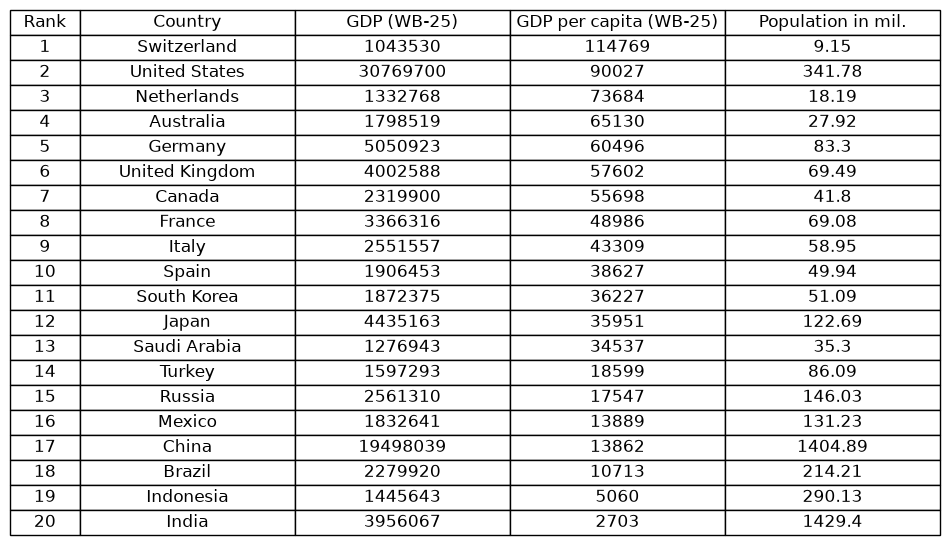

In [44]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.axis("off")

n=0.075
table = ax.table(
    cellText=temp_df.values,
    colLabels=temp_df.columns,
    cellLoc="center",
    loc="center",
    colWidths=[n]+[(1-n)/4 for i in range(4)]
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.5)

plt.savefig("Figures/Country_table.png", dpi=300, bbox_inches="tight")
plt.show()